# 02 · Manifold — Giustacchini 2017 CML

Fit a cell-state trajectory on the primary malignant manifold. **Test branching honestly**: fit a
scFates PPT **tree** first and inspect its fork biology; only fit a **curve** if the manifold is truly
non-branching. Root from the **developmental order** the signatures imply (gastrulation/somitogenesis
origin; neural crest is a *late* readout), and validate the fit — render the curve, check it is
fold-free, and confirm continuity on an **independent** embedding (diffusion map), not the UMAP being
tested. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load manifold + score developmental signatures
Score the three embryonic modules (Gast, pSom, Crest) with `score_genes` against the union control
pool, then **graph-smooth** the scores over the kNN connectivity graph (3 averaging passes) so geography
and correlations are read from a denoised field rather than per-cell noise (raw scores are shown in the
03 signature deliverables).

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('primary malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; cc = xy - xy.mean(0)
from numpy.linalg import svd
u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

primary malignant manifold: 1845 cells
UMAP aspect ratio (major/minor std): 3.05
Gast: 69/81 genes present
pSom: 75/98 genes present
Crest: 95/104 genes present


### Geography of the smoothed signatures
The dominant axis is **Gast ↔ Crest** cross-opposition (spatial r ≈ −0.88): a gastrulation-high pole
opposes a neural-crest-high pole, with pSom co-varying weakly. Gast and pSom are nearly orthogonal (r ≈
−0.04) — they do not resolve into two competing arms — while Crest is the terminal readout opposing
both. This is the signature of a **single developmental axis** rather than a Gast/pSom bifurcation.

In [4]:
print('smoothed spatial correlations on the primary manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.3f}')
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S','G2/M','Intermediate'])
print('\ncycling confound check (raw signature vs cell-cycle score):')
for m in ['Gast','pSom','Crest']:
    r = np.corrcoef(adata.obs[m], adata.obs['cyc_score'])[0,1]; print(f'  {m} vs cyc_score: r = {r:+.3f}')
print('cycling fraction: %.3f -- Crest terminus is not a proliferation artefact (Crest vs cyc ~ 0)' % adata.obs['cycling'].mean())

smoothed spatial correlations on the primary manifold:
  Gast_sm vs pSom_sm: r = -0.042
  Crest_sm vs Gast_sm: r = -0.883
  Crest_sm vs pSom_sm: r = -0.373

cycling confound check (raw signature vs cell-cycle score):
  Gast vs cyc_score: r = -0.230
  pSom vs cyc_score: r = +0.004
  Crest vs cyc_score: r = +0.084
cycling fraction: 0.151 -- Crest terminus is not a proliferation artefact (Crest vs cyc ~ 0)


### Honest branching test — PPT tree fork biology
Fit a scFates PPT **tree** and inspect its tips/forks. Across parameter settings the tree returns **two
tips and zero forks** — a Gast-higher/Crest-low pole and a Gast-low/Crest-high pole, with pSom flat
across both. There is **no Gast/pSom co-expression hub and no opposing Gast arm**, so the manifold is
non-branching: we fit a **curve**, not a tree (do not fit a tree on a strip).

In [5]:
ad_t = adata.copy()
sig0 = 0.1*np.ptp(ad_t.obsm['X_umap'])
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad_t, Nodes=20, use_rep='X_umap', method='ppt', ppt_lambda=100,
                ppt_sigma=sig0, seed=SEED, plot=False)
Bt = np.asarray(ad_t.uns['graph']['B']); degt = (Bt>0).sum(0)
tips_t = np.where(degt==1)[0]; forks_t = np.where(degt>=3)[0]
Dt = shortest_path(sp.csr_matrix((Bt>0).astype(int)), unweighted=True)
hard_t = np.asarray(ad_t.obsm['X_R']).argmax(1)
print(f'PPT tree: {len(tips_t)} tips, {len(forks_t)} fork(s) -> inspect node biology:')
for grp,node in [('tip%d'%t,t) for t in tips_t] + [('fork%d'%f,f) for f in forks_t]:
    m = np.isin(hard_t, np.where(Dt[node]<=2)[0])
    if m.sum()==0: continue
    print(f'  {grp}: n={int(m.sum()):4d} Gast={adata.obs["Gast_sm"][m].mean():+.4f} '
          f'pSom={adata.obs["pSom_sm"][m].mean():+.4f} Crest={adata.obs["Crest_sm"][m].mean():+.4f}')
print('no Gast/pSom co-expression hub, no opposing Gast arm -> non-branching (fit a curve).')

PPT tree: 2 tips, 0 fork(s) -> inspect node biology:
  tip17: n= 364 Gast=-0.0128 pSom=+0.0311 Crest=-0.0693
  tip19: n= 320 Gast=-0.1859 pSom=+0.0405 Crest=+0.0197
no Gast/pSom co-expression hub, no opposing Gast arm -> non-branching (fit a curve).


### Fit the principal curve + fold check
Fit a scFates principal **curve** and check topology: it must have zero forks and be fold-free (the
minimum Euclidean approach between graph-distant nodes exceeds the median edge length). A self-approach
ratio > 1 means the curve does not double back through the cloud.

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"


curve: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)


### Root from developmental order + pseudotime
Root at the tip with the highest Gast+pSom and lowest Crest — the gastrulation/somitogenesis origin
(neural crest is *late*, so it is never the root). Pseudotime then runs origin → Crest-high terminus.

In [7]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('\ngradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,pv = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f} p={pv:.1e}')

tip 0: Gast=-0.0215 pSom=+0.0353 Crest=-0.0687
tip 2: Gast=-0.1667 pSom=+0.0428 Crest=+0.0116
derived root = tip 0 (Gast/pSom-high, Crest-low = developmental origin)

gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.959 p=0.0e+00
  pSom_sm: rho=+0.202 p=1.7e-18
  Crest_sm: rho=+0.787 p=0.0e+00


### Continuity on an independent embedding
Confirm the trajectory is one continuous progression using a diffusion map computed independently of the
UMAP under test: |corr(pseudotime, DC1)| ≥ 0.8 on a single diffusion component certifies continuity
without reading neighbours off the embedding being judged.

In [8]:
sc.tl.diffmap(adata)
r_dc1 = abs(np.corrcoef(t, adata.obsm['X_diffmap'][:,1])[0,1])
r_dc2 = abs(np.corrcoef(t, adata.obsm['X_diffmap'][:,2])[0,1])
print(f'|corr(pseudotime, DC1)| = {r_dc1:.2f} | DC2 = {r_dc2:.2f} (>=0.8 on a component = continuous)')
assert max(r_dc1, r_dc2) > 0.8, "continuity check failed"
tn = (t-t.min())/(t.max()-t.min())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')

|corr(pseudotime, DC1)| = 0.98 | DC2 = 0.05 (>=0.8 on a component = continuous)
neural-crest-high decile mean pseudotime = 0.98 (terminal if ~1)


### Orient pseudotime left→right (house layout)
Re-use the rigid `X_umap_lin` rotation from 01 and, if needed, flip so pseudotime increases left→right
(root at left). Distances are preserved — no re-embedding of the linear compartment.

In [9]:
xyr = adata.obsm['X_umap_lin'].copy()
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
adata.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (root at left)')

orientation: corr(x_lin, pseudotime) = +0.99 (root at left)


### Render the fitted curve on the embedding + save

saved manifold.h5ad + manifold.pdf (curve edges rendered)


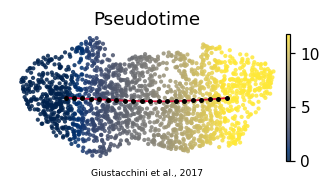

In [10]:
from scipy.sparse.csgraph import minimum_spanning_tree
sub = adata
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
# project curve nodes into the house-oriented layout for rendering
xy = sub.obsm['X_umap']; c0 = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c0, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
F = np.asarray(sub.uns['graph']['F']).T
Fr = (F - xy.mean(0)) @ Rm.T
flip = np.corrcoef(sub.obsm['X_umap_lin'][:,0], (c0@Rm.T)[:,0])[0,1] < 0
if flip: Fr[:,0] = -Fr[:,0]
Bc = np.asarray(sub.uns['graph']['B'])
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ii,jj = np.where(np.triu(Bc>0))
for a,b in zip(ii,jj):
    ax.plot([Fr[a,0],Fr[b,0]],[Fr[a,1],Fr[b,1]], '-', color='crimson', lw=1.1, zorder=5)
ax.scatter(Fr[:,0],Fr[:,1], s=5, color='black', zorder=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Giustacchini et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf (curve edges rendered)')